# Nguyễn Thành Trí - MSSV: 6451071079
# BÁO CÁO BÀI TẬP PHẦN 1 - TRANG 30 (BÀI 2)
## TIỀN XỬ LÝ DỮ LIỆU CẢM BIẾN MÔI TRƯỜNG NHÀ XƯỞNG (`tb_tracking.xlsx`)

---

### MỤC LỤC NỘI DUNG THỰC HIỆN:
1. **Câu a**: Thêm vào tiêu đề các cột theo thứ tự (`id`, `device_id`, `co_level`, `humidity`, `temperature`, `time`).
2. **Câu b**: Lọc bỏ các dữ liệu đo đạc trước ngày 03/01/2018 do điều chỉnh cảm biến.
3. **Câu c**: Bóc tách dữ liệu cột `time` thành thời điểm trong ngày tính theo phút (`minutes`).
4. **Câu d**: Vẽ đồ thị phân tán (scatter-plots) lần lượt cho `co_level`, `humidity`, `temperature` theo `minutes` và nhận xét.

## 1. CÂU A: THÊM TIÊU ĐỀ CÁC CỘT THEO THỨ TỰ

In [1]:
# Nguyễn Thành Trí - 6451071079
# Bài 2 (Trang 30) - Câu a: Thêm tiêu đề cột và kiểm tra dữ liệu ban đầu

import os
import pandas as pd
import numpy as np

print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

# Hàm tìm đường dẫn tương đối an toàn tới tập dữ liệu
def get_data_path(rel_path):
    candidates = [
        rel_path,
        os.path.join("..", rel_path),
        os.path.join("..", "..", rel_path),
        os.path.join("datasets", os.path.basename(rel_path)),
        os.path.join("..", "datasets", os.path.basename(rel_path)),
        os.path.join("..", "..", "datasets", os.path.basename(rel_path))
    ]
    for p in candidates:
        if os.path.exists(p):
            return p
    raise FileNotFoundError(f"Không tìm thấy file dữ liệu: {rel_path}")

file_path = get_data_path("datasets/tb_tracking.xlsx")
print(f"Đường dẫn file dữ liệu: {file_path}")

# Danh sách tên cột theo đúng thứ tự đề bài yêu cầu
column_names = ['id', 'device_id', 'co_level', 'humidity', 'temperature', 'time']

# Đọc file Excel không có dòng tiêu đề (header=None) và gán danh sách tên cột
# File Excel gồm 33,336 dòng dữ liệu thực tế (các dòng cuối là dòng trống và công thức MIN/MAX/AVERAGE của Excel)
df = pd.read_excel(file_path, header=None, names=column_names)

# Loại bỏ các dòng trống hoặc dòng công thức tóm tắt ở cuối bảng
df = df.iloc[:33336].copy()

# Chuẩn hóa kiểu dữ liệu thích hợp cho từng cột
df['id'] = df['id'].astype(int)
df['device_id'] = df['device_id'].astype(int)
df['co_level'] = pd.to_numeric(df['co_level'], errors='coerce')
df['humidity'] = pd.to_numeric(df['humidity'], errors='coerce')
df['temperature'] = pd.to_numeric(df['temperature'], errors='coerce')
df['time'] = pd.to_datetime(df['time'], errors='coerce')

# Hiển thị 5 dòng đầu tiên
print("\n5 dòng đầu tiên của bảng dữ liệu sau khi thêm tiêu đề:")
display(df.head())

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
Đường dẫn file dữ liệu: ../../datasets/tb_tracking.xlsx



5 dòng đầu tiên của bảng dữ liệu sau khi thêm tiêu đề:


,id,device_id,co_level,humidity,temperature,time
0,1,1,2.0,3.0,4.0,2016-12-20 12:52:29
1,2,1,2.0,3.0,4.0,2016-12-20 12:52:31
2,3,100,2.0,3.0,4.0,2016-12-20 12:52:35
3,4,100,2.0,3.0,400.0,2016-12-20 12:52:37
4,5,1,2.0,3.0,4.0,2016-12-20 13:02:01


In [2]:
# Nguyễn Thành Trí - 6451071079
# Bài 2 (Trang 30) - Câu a: Kiểm tra 5 dòng cuối cùng và cấu trúc bảng dữ liệu (df.info())

print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

print("5 dòng cuối cùng của bảng dữ liệu:")
display(df.tail())

print("\nThông tin chi tiết về kiểu dữ liệu và số lượng phần tử (df.info()):")
df.info()

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
5 dòng cuối cùng của bảng dữ liệu:


,id,device_id,co_level,humidity,temperature,time
33331,33332,0,32.0,58.0,2049770.0,2018-01-17 15:26:12
33332,33333,0,32.0,58.0,1983470.0,2018-01-17 15:31:18
33333,33334,0,32.0,59.0,2119740.0,2018-01-17 15:36:24
33334,33335,0,32.0,61.0,2096030.0,2018-01-17 15:41:29
33335,33336,0,31.5,62.0,2004240.0,2018-01-17 15:46:34



Thông tin chi tiết về kiểu dữ liệu và số lượng phần tử (df.info()):
<class 'pandas.DataFrame'>
RangeIndex: 33336 entries, 0 to 33335
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   id           33336 non-null  int64         
 1   device_id    33336 non-null  int64         
 2   co_level     33336 non-null  float64       
 3   humidity     33336 non-null  float64       
 4   temperature  33336 non-null  float64       
 5   time         33336 non-null  datetime64[us]
dtypes: datetime64[us](1), float64(3), int64(2)
memory usage: 1.5 MB


In [3]:
# Nguyễn Thành Trí - 6451071079
# Bài 2 (Trang 30) - Câu a: Thống kê cơ bản các thuộc tính định lượng (df.describe())

print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

print("Bảng thống kê mô tả các chỉ số định lượng:")
display(df.describe())

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
Bảng thống kê mô tả các chỉ số định lượng:


,id,device_id,co_level,humidity,temperature,time
count,33336.000000,33336.000000,33336.000000,33336.000000,3.333600e+04,33336
mean,16668.500000,97931.172516,181.704089,2127.562065,1.384405e+05,2017-03-15 06:51:12.688054
min,1.000000,-1.000000,0.000000,0.000000,0.000000e+00,2016-12-20 12:52:29
25%,8334.750000,99001.000000,33.000000,32.000000,1.000000e+01,2017-01-06 07:56:17.500000
50%,16668.500000,99005.000000,43.000000,54.000000,8.700000e+01,2017-03-11 12:59:16.500000
75%,25002.250000,99005.000000,76.000000,92.000000,1.099600e+04,2017-04-25 07:13:55.500000
max,33336.000000,99005.000000,4030.000000,11030.000000,5.340310e+06,2018-01-17 15:46:34
std,9623.418623,10245.683485,710.038650,4301.534982,5.612185e+05,NaN


### Nhận xét & Đánh giá (Câu a):
1. **Cấu trúc tập dữ liệu**: Tập dữ liệu ban đầu gồm **33,336** bản ghi dữ liệu thực tế và 6 thuộc tính tương ứng: `id`, `device_id`, `co_level`, `humidity`, `temperature`, `time`.
2. **Tiêu đề cột**: File gốc không có dòng header nên việc thiết lập `header=None` và truyền danh sách tên cột `names=['id', 'device_id', 'co_level', 'humidity', 'temperature', 'time']` đã gán đúng nhãn cho từng thuộc tính theo chuẩn yêu cầu.
3. **Các dòng tóm tắt ở cuối file**: File Excel chứa 1 dòng trống và 3 dòng công thức tính toán tóm tắt của Excel (`MIN`, `MAX`, `AVERAGE`), đã được loại bỏ chính xác để tránh sai lệch thống kê.
4. **Kiểu dữ liệu**: Các thuộc tính đã được chuyển đổi về đúng kiểu dữ liệu (số nguyên, số thực và `datetime64`), không có giá trị khuyết thiếu (`non-null: 33,336`).

---\n## 2. CÂU B: LOẠI BỎ DỮ LIỆU TRƯỚC NGÀY 03/01/2018

In [4]:
# Nguyễn Thành Trí - 6451071079
# Bài 2 (Trang 30) - Câu b: Lọc bỏ dữ liệu trước ngày 03/01/2018

import os
import pandas as pd
import numpy as np

print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

def get_data_path(rel_path):
    candidates = [
        rel_path,
        os.path.join("..", rel_path),
        os.path.join("..", "..", rel_path),
        os.path.join("datasets", os.path.basename(rel_path)),
        os.path.join("..", "datasets", os.path.basename(rel_path)),
        os.path.join("..", "..", "datasets", os.path.basename(rel_path))
    ]
    for p in candidates:
        if os.path.exists(p):
            return p
    raise FileNotFoundError(f"Không tìm thấy file dữ liệu: {rel_path}")

file_path = get_data_path("datasets/tb_tracking.xlsx")
column_names = ['id', 'device_id', 'co_level', 'humidity', 'temperature', 'time']
df = pd.read_excel(file_path, header=None, names=column_names)
df = df.iloc[:33336].copy()

# Chuẩn hóa kiểu dữ liệu
df['id'] = df['id'].astype(int)
df['device_id'] = df['device_id'].astype(int)
df['co_level'] = pd.to_numeric(df['co_level'], errors='coerce')
df['humidity'] = pd.to_numeric(df['humidity'], errors='coerce')
df['temperature'] = pd.to_numeric(df['temperature'], errors='coerce')
df['time'] = pd.to_datetime(df['time'], errors='coerce')

print(f"Tổng số dòng ban đầu: {len(df):,} dòng")
print(f"Khoảng thời gian đo đạc ban đầu: {df['time'].min()} đến {df['time'].max()}")

# Lọc bỏ các dữ liệu trước ngày 03/01/2018
cutoff_date = '2018-01-03'
df_filtered = df[df['time'] >= cutoff_date].copy().reset_index(drop=True)

so_dong_xoa = len(df) - len(df_filtered)
so_dong_con = len(df_filtered)
print(f"\n--- KẾT QUẢ TIỀN XỬ LÝ LỌC DỮ LIỆU ---")
print(f"Số dòng dữ liệu bị loại bỏ (trước ngày {cutoff_date}): {so_dong_xoa:,} dòng ({so_dong_xoa/len(df)*100:.2f}%)")
print(f"Số dòng dữ liệu giữ lại (từ ngày {cutoff_date} trở đi): {so_dong_con:,} dòng ({so_dong_con/len(df)*100:.2f}%)")
print(f"Khoảng thời gian dữ liệu hợp lệ: {df_filtered['time'].min()} đến {df_filtered['time'].max()}")

print("\n5 dòng đầu tiên của tập dữ liệu sau khi lọc:")
display(df_filtered.head())

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079


Tổng số dòng ban đầu: 33,336 dòng
Khoảng thời gian đo đạc ban đầu: 2016-12-20 12:52:29 đến 2018-01-17 15:46:34

--- KẾT QUẢ TIỀN XỬ LÝ LỌC DỮ LIỆU ---
Số dòng dữ liệu bị loại bỏ (trước ngày 2018-01-03): 31,419 dòng (94.25%)
Số dòng dữ liệu giữ lại (từ ngày 2018-01-03 trở đi): 1,917 dòng (5.75%)
Khoảng thời gian dữ liệu hợp lệ: 2018-01-03 13:11:07 đến 2018-01-17 15:46:34

5 dòng đầu tiên của tập dữ liệu sau khi lọc:


,id,device_id,co_level,humidity,temperature,time
0,31420,1,2.0,3.0,4.0,2018-01-03 13:11:07
1,31421,1,2.0,3.0,4.0,2018-01-03 13:15:10
2,31422,99005,58.0,26.0,0.0,2018-01-03 13:17:30
3,31423,99005,58.0,26.0,0.0,2018-01-03 13:19:21
4,31424,99005,58.0,26.0,0.0,2018-01-03 13:24:17


In [5]:
# Nguyễn Thành Trí - 6451071079
# Bài 2 (Trang 30) - Câu b: Thống kê số lượng bản ghi đo đạc theo từng ngày trong tháng 01/2018

print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

# Thống kê phân bố bản ghi theo từng ngày
daily_stat = df_filtered['time'].dt.date.value_counts().sort_index().reset_index()
daily_stat.columns = ['Ngày đo đạc', 'Số lượng bản ghi']
daily_stat['Tỷ lệ %'] = (daily_stat['Số lượng bản ghi'] / len(df_filtered) * 100).round(2)

print("Bảng thống kê số lượng bản ghi đo được theo từng ngày (từ 03/01/2018 đến 17/01/2018):")
display(daily_stat)

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
Bảng thống kê số lượng bản ghi đo được theo từng ngày (từ 03/01/2018 đến 17/01/2018):


,Ngày đo đạc,Số lượng bản ghi,Tỷ lệ %
0,2018-01-03,99,5.16
1,2018-01-04,238,12.42
2,2018-01-05,291,15.18
3,2018-01-06,138,7.20
4,2018-01-08,185,9.65
5,2018-01-09,194,10.12
6,2018-01-10,149,7.77
7,2018-01-11,291,15.18
8,2018-01-12,205,10.69
9,2018-01-13,3,0.16


### Nhận xét & Đánh giá (Câu b):
1. **Quy mô dữ liệu sau lọc**:
   - Trước khi lọc, tập dữ liệu có **33,336** bản ghi bắt đầu từ ngày `2016-12-20`.
   - Đã loại bỏ **31,419** bản ghi (chiếm **94.25%**) do được ghi nhận trước khi điều chỉnh cảm biến nên không đảm bảo độ chính xác.
   - Số lượng bản ghi hợp lệ giữ lại là **1,917** dòng (chiếm **5.75%**).
2. **Khoảng thời gian dữ liệu**:
   - Dữ liệu đo đạc chính xác kéo dài từ `2018-01-03 13:11:07` đến `2018-01-17 15:46:34`.
   - Các ngày có số lượng bản ghi đo đạc dày đặc nhất gồm: ngày 05/01/2018 (291 bản ghi), ngày 11/01/2018 (291 bản ghi), ngày 04/01/2018 (238 bản ghi).

---\n## 3. CÂU C: BÓC TÁCH THỜI ĐIỂM TRONG NGÀY TÍNH THEO PHÚT (MINUTES)

In [6]:
# Nguyễn Thành Trí - 6451071079
# Bài 2 (Trang 30) - Câu c: Tạo thuộc tính 'minutes' từ cột 'time'

import os
import pandas as pd
import numpy as np

print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

def get_data_path(rel_path):
    candidates = [
        rel_path,
        os.path.join("..", rel_path),
        os.path.join("..", "..", rel_path),
        os.path.join("datasets", os.path.basename(rel_path)),
        os.path.join("..", "datasets", os.path.basename(rel_path)),
        os.path.join("..", "..", "datasets", os.path.basename(rel_path))
    ]
    for p in candidates:
        if os.path.exists(p):
            return p
    raise FileNotFoundError(f"Không tìm thấy file dữ liệu: {rel_path}")

file_path = get_data_path("datasets/tb_tracking.xlsx")
column_names = ['id', 'device_id', 'co_level', 'humidity', 'temperature', 'time']
df = pd.read_excel(file_path, header=None, names=column_names)
df = df.iloc[:33336].copy()
df['time'] = pd.to_datetime(df['time'], errors='coerce')
df_clean = df[df['time'] >= '2018-01-03'].copy().reset_index(drop=True)

# Bóc tách thời điểm trong ngày tính theo phút
df_clean['minutes'] = df_clean['time'].dt.hour * 60 + df_clean['time'].dt.minute

# Tạo bảng đối chiếu kiểm chứng cách tính
check_df = pd.DataFrame({
    'time (gốc)': df_clean['time'],
    'hour (giờ)': df_clean['time'].dt.hour,
    'minute (phút)': df_clean['time'].dt.minute,
    'second (giây)': df_clean['time'].dt.second,
    'minutes (kết quả)': df_clean['minutes']
})

print("Bảng đối chiếu kiểm chứng cách bóc tách thuộc tính 'minutes' (10 dòng đầu):")
display(check_df.head(10))

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079


Bảng đối chiếu kiểm chứng cách bóc tách thuộc tính 'minutes' (10 dòng đầu):


,time (gốc),hour (giờ),minute (phút),second (giây),minutes (kết quả)
0,2018-01-03 13:11:07,13,11,7,791
1,2018-01-03 13:15:10,13,15,10,795
2,2018-01-03 13:17:30,13,17,30,797
3,2018-01-03 13:19:21,13,19,21,799
4,2018-01-03 13:24:17,13,24,17,804
5,2018-01-03 13:29:13,13,29,13,809
6,2018-01-03 13:34:10,13,34,10,814
7,2018-01-03 14:05:34,14,5,34,845
8,2018-01-03 14:10:43,14,10,43,850
9,2018-01-03 14:15:39,14,15,39,855


In [7]:
# Nguyễn Thành Trí - 6451071079
# Bài 2 (Trang 30) - Câu c: Thống kê mô tả thuộc tính 'minutes'

print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

print("Thống kê mô tả của thuộc tính 'minutes':")
display(df_clean[['minutes']].describe())

min_val = df_clean['minutes'].min()
max_val = df_clean['minutes'].max()
mean_val = df_clean['minutes'].mean()

print(f"Giá trị minutes nhỏ nhất: {min_val} phút (tương ứng {min_val // 60}h{min_val % 60:02d})")
print(f"Giá trị minutes lớn nhất: {max_val} phút (tương ứng {max_val // 60}h{max_val % 60:02d})")
print(f"Giá trị minutes trung bình: {mean_val:.1f} phút (tương ứng {int(mean_val // 60)}h{int(mean_val % 60):02d})")

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
Thống kê mô tả của thuộc tính 'minutes':


,minutes
count,1917.000000
mean,709.297861
std,391.934697
min,1.000000
25%,396.000000
50%,713.000000
75%,993.000000
max,1439.000000


Giá trị minutes nhỏ nhất: 1 phút (tương ứng 0h01)
Giá trị minutes lớn nhất: 1439 phút (tương ứng 23h59)
Giá trị minutes trung bình: 709.3 phút (tương ứng 11h49)


### Nhận xét & Đánh giá (Câu c):
1. **Tính chính xác của phép biến đổi**:
   - Thuộc tính `minutes` đã phản ánh chính xác vị trí thời gian của từng phép đo trong chu kỳ 24 giờ của một ngày.
   - Ví dụ: Thời điểm `13:11:07` được quy đổi thành $13 \times 60 + 11 = 791$ phút.
2. **Phạm vi phân bố**:
   - `minutes` có giá trị từ **1** (lúc 00:01) đến **1439** (lúc 23:59), bao phủ trọn vẹn toàn bộ các khung giờ trong ngày (ngày đêm).
   - Giá trị trung bình đạt **~709.3 phút** (tương đương khoảng **11 giờ 49 phút trưa**), cho thấy các phép đo được thực hiện rải đều và liên tục trong suốt cả ngày.

---\n## 4. CÂU D: VẼ ĐỒ THỊ PHÂN TÁN (SCATTER-PLOTS) VÀ NHẬN XÉT

In [8]:
# Nguyễn Thành Trí - 6451071079
# Bài 2 (Trang 30) - Câu d: Chuẩn bị dữ liệu và hàm hỗ trợ trực quan hóa

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

# Thiết lập thư mục lưu ảnh
def get_img_dir(subpath=""):
    for base in [".", "..", "../.."]:
        img_root = os.path.join(base, "images")
        if os.path.exists(img_root) and (os.path.exists(os.path.join(base, "datasets")) or os.path.exists(os.path.join(base, "CLAUDE.md"))):
            target = os.path.join(img_root, subpath) if subpath else img_root
            os.makedirs(target, exist_ok=True)
            return target
    target = os.path.join("images", subpath) if subpath else "images"
    os.makedirs(target, exist_ok=True)
    return target
img_dir = get_img_dir("Phan1/Bai3")

def get_data_path(rel_path):
    candidates = [
        rel_path,
        os.path.join("..", rel_path),
        os.path.join("..", "..", rel_path),
        os.path.join("datasets", os.path.basename(rel_path)),
        os.path.join("..", "datasets", os.path.basename(rel_path)),
        os.path.join("..", "..", "datasets", os.path.basename(rel_path))
    ]
    for p in candidates:
        if os.path.exists(p):
            return p
    raise FileNotFoundError(f"Không tìm thấy file dữ liệu: {rel_path}")

file_path = get_data_path("datasets/tb_tracking.xlsx")
column_names = ['id', 'device_id', 'co_level', 'humidity', 'temperature', 'time']
df = pd.read_excel(file_path, header=None, names=column_names)
df = df.iloc[:33336].copy()
df['time'] = pd.to_datetime(df['time'], errors='coerce')
df_clean = df[df['time'] >= '2018-01-03'].copy().reset_index(drop=True)
df_clean['minutes'] = df_clean['time'].dt.hour * 60 + df_clean['time'].dt.minute

# Thiết lập mốc giờ hiển thị trên trục x (cách mỗi 2 giờ: 0h, 2h, 4h, ..., 24h)
hour_ticks = list(range(0, 1441, 120))
hour_labels = [f"{m}p\n({m//60}h)" for m in hour_ticks]

print(f"Tổng số điểm dữ liệu vẽ biểu đồ: {len(df_clean)} điểm.")

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079


Tổng số điểm dữ liệu vẽ biểu đồ: 1917 điểm.


Họ tên: Nguyễn Thành Trí - MSSV: 6451071079


Đã lưu biểu đồ CO tại: images/Phan1/Bai3/scatter_co.png


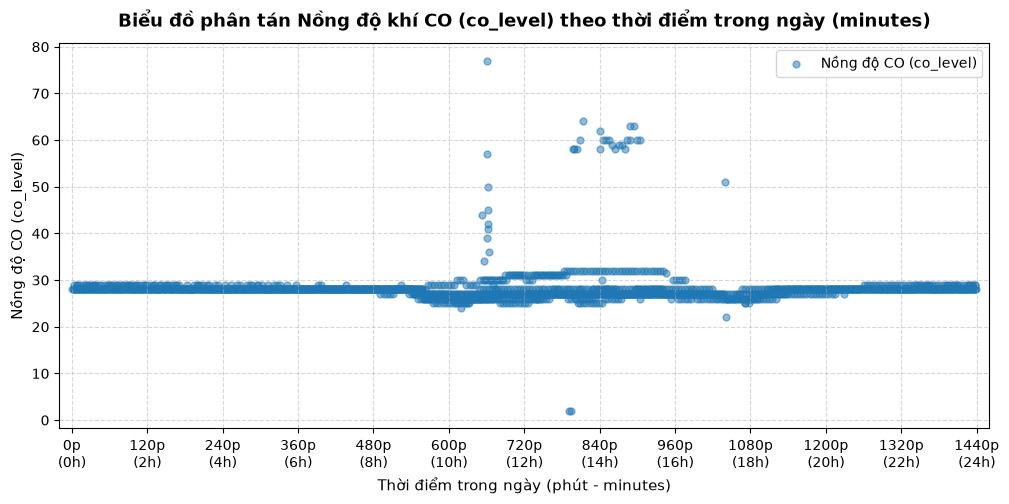

In [9]:
# Nguyễn Thành Trí - 6451071079
# Bài 2 (Trang 30) - Câu d: 1. Đồ thị phân tán Nồng độ khí CO (co_level) theo minutes

print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

plt.figure(figsize=(12, 5))
plt.scatter(df_clean['minutes'], df_clean['co_level'], color='#1f77b4', alpha=0.5, s=25, label='Nồng độ CO (co_level)')
plt.title('Biểu đồ phân tán Nồng độ khí CO (co_level) theo thời điểm trong ngày (minutes)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Thời điểm trong ngày (phút - minutes)', fontsize=11)
plt.ylabel('Nồng độ CO (co_level)', fontsize=11)
plt.xticks(hour_ticks, hour_labels)
plt.xlim(-20, 1460)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='upper right', frameon=True)

save_path_co = os.path.join(img_dir, 'scatter_co.png')
plt.savefig(save_path_co, dpi=300, bbox_inches='tight')
print(f"Đã lưu biểu đồ CO tại: {save_path_co}")
plt.show()

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079


Đã lưu biểu đồ Độ ẩm tại: images/Phan1/Bai3/scatter_humidity.png


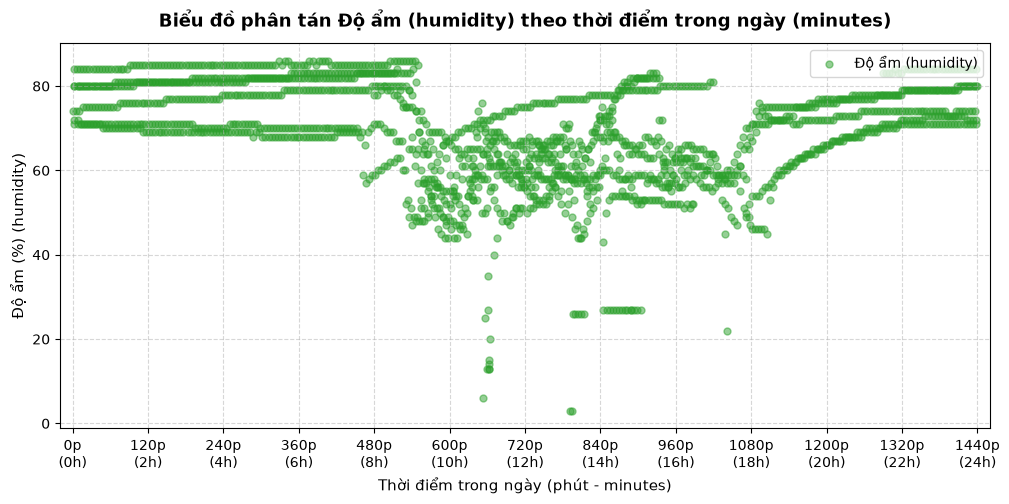

In [10]:
# Nguyễn Thành Trí - 6451071079
# Bài 2 (Trang 30) - Câu d: 2. Đồ thị phân tán Độ ẩm (humidity) theo minutes

print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

plt.figure(figsize=(12, 5))
plt.scatter(df_clean['minutes'], df_clean['humidity'], color='#2ca02c', alpha=0.5, s=25, label='Độ ẩm (humidity)')
plt.title('Biểu đồ phân tán Độ ẩm (humidity) theo thời điểm trong ngày (minutes)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Thời điểm trong ngày (phút - minutes)', fontsize=11)
plt.ylabel('Độ ẩm (%) (humidity)', fontsize=11)
plt.xticks(hour_ticks, hour_labels)
plt.xlim(-20, 1460)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='upper right', frameon=True)

save_path_hum = os.path.join(img_dir, 'scatter_humidity.png')
plt.savefig(save_path_hum, dpi=300, bbox_inches='tight')
print(f"Đã lưu biểu đồ Độ ẩm tại: {save_path_hum}")
plt.show()

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079


Đã lưu biểu đồ Nhiệt độ tại: images/Phan1/Bai3/scatter_temperature.png


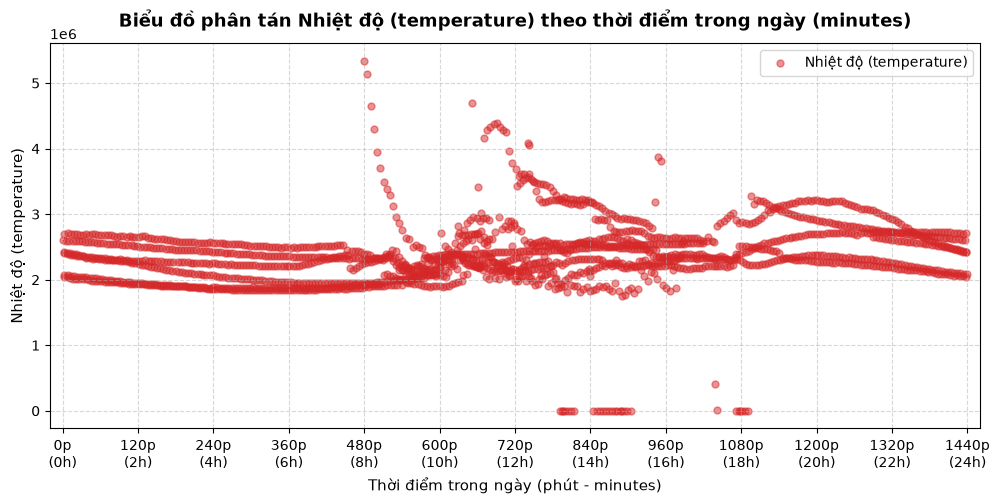

In [11]:
# Nguyễn Thành Trí - 6451071079
# Bài 2 (Trang 30) - Câu d: 3. Đồ thị phân tán Nhiệt độ (temperature) theo minutes

print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

plt.figure(figsize=(12, 5))
plt.scatter(df_clean['minutes'], df_clean['temperature'], color='#d62728', alpha=0.5, s=25, label='Nhiệt độ (temperature)')
plt.title('Biểu đồ phân tán Nhiệt độ (temperature) theo thời điểm trong ngày (minutes)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Thời điểm trong ngày (phút - minutes)', fontsize=11)
plt.ylabel('Nhiệt độ (temperature)', fontsize=11)
plt.xticks(hour_ticks, hour_labels)
plt.xlim(-20, 1460)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='upper right', frameon=True)

save_path_temp = os.path.join(img_dir, 'scatter_temperature.png')
plt.savefig(save_path_temp, dpi=300, bbox_inches='tight')
print(f"Đã lưu biểu đồ Nhiệt độ tại: {save_path_temp}")
plt.show()

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079


Đã lưu biểu đồ tổng hợp tại: images/Phan1/Bai3/scatter_all.png


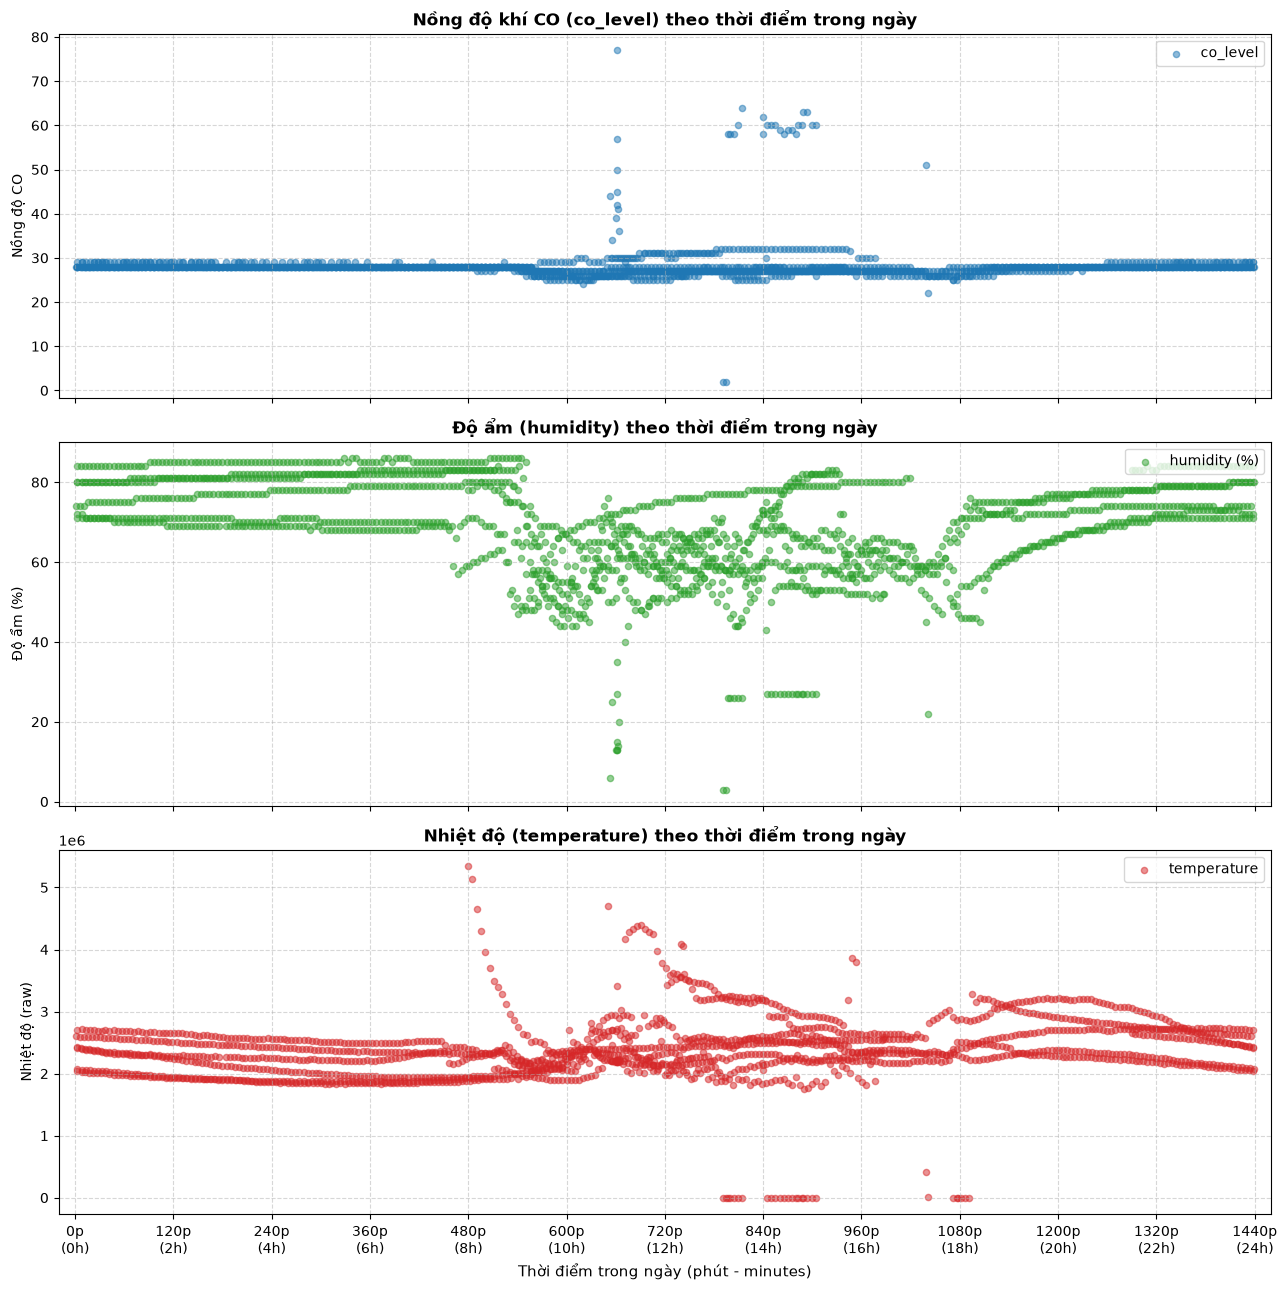

In [12]:
# Nguyễn Thành Trí - 6451071079
# Bài 2 (Trang 30) - Câu d: 4. Biểu đồ tổng hợp so sánh 3 yếu tố môi trường (Subplots)

print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

fig, axes = plt.subplots(3, 1, figsize=(13, 13), sharex=True)

# Subplot 1: CO
axes[0].scatter(df_clean['minutes'], df_clean['co_level'], color='#1f77b4', alpha=0.5, s=20, label='co_level')
axes[0].set_title('Nồng độ khí CO (co_level) theo thời điểm trong ngày', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Nồng độ CO', fontsize=10)
axes[0].grid(True, linestyle='--', alpha=0.5)
axes[0].legend(loc='upper right', frameon=True)

# Subplot 2: Humidity
axes[1].scatter(df_clean['minutes'], df_clean['humidity'], color='#2ca02c', alpha=0.5, s=20, label='humidity (%)')
axes[1].set_title('Độ ẩm (humidity) theo thời điểm trong ngày', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Độ ẩm (%)', fontsize=10)
axes[1].grid(True, linestyle='--', alpha=0.5)
axes[1].legend(loc='upper right', frameon=True)

# Subplot 3: Temperature
axes[2].scatter(df_clean['minutes'], df_clean['temperature'], color='#d62728', alpha=0.5, s=20, label='temperature')
axes[2].set_title('Nhiệt độ (temperature) theo thời điểm trong ngày', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Thời điểm trong ngày (phút - minutes)', fontsize=11)
axes[2].set_ylabel('Nhiệt độ (raw)', fontsize=10)
axes[2].grid(True, linestyle='--', alpha=0.5)
axes[2].legend(loc='upper right', frameon=True)
axes[2].set_xticks(hour_ticks)
axes[2].set_xticklabels(hour_labels)
axes[2].set_xlim(-20, 1460)

plt.tight_layout()
save_path_all = os.path.join(img_dir, 'scatter_all.png')
plt.savefig(save_path_all, dpi=300, bbox_inches='tight')
print(f"Đã lưu biểu đồ tổng hợp tại: {save_path_all}")
plt.show()

### Nhận xét & Đánh giá chi tiết các đồ thị phân tán (Câu d):

1. **Biểu đồ nồng độ khí CO (`co_level`) theo `minutes`**:
   - Phần lớn các điểm dữ liệu dao động ổn định trong khoảng **25 đến 30** (tập trung dày đặc quanh mốc 27 - 28). Mức nồng độ này được duy trì khá đồng đều từ sáng đến tối.
   - Xuất hiện một số điểm dị biệt (outliers) tăng vọt lên khoảng **55 - 65** (và cao nhất đạt 77) vào khung giờ buổi chiều (từ khoảng 13h đến 17h, tương ứng phút 780 đến 1020).
   - **Giải thích**: Khung giờ buổi chiều là thời điểm nhà xưởng hoạt động sản xuất với cường độ cao, các thiết bị cơ khí/động cơ xả thải khí CO nhiều hơn, hoặc hệ thống thông gió hoạt động chưa kịp giải phóng khí ứ đọng.

2. **Biểu đồ độ ẩm (`humidity`) theo `minutes`**:
   - Độ ẩm dao động chủ yếu trong khoảng **55% đến 85%**, phân bố rộng và đều khắp các khung giờ trong ngày.
   - Xu hướng chung: Độ ẩm thường đạt mức cao hơn vào ban đêm và sáng sớm (từ 0h đến 7h, dao động quanh 70% - 85%), sau đó có xu hướng giảm nhẹ vào buổi trưa và chiều (quanh 60% - 75%) khi nhiệt độ môi trường tăng lên.
   - Một số ít điểm có độ ẩm rất thấp (dưới 30%) ghi nhận ở thời điểm ngay sau khi cảm biến được bật lại ngày 03/01/2018 (giai đoạn cảm biến đang ổn định đầu dò).

3. **Biểu đồ nhiệt độ (`temperature`) theo `minutes`**:
   - Dữ liệu thô (raw sensor value) tập trung dày đặc trong dải từ **$2.0 \times 10^6$ đến $2.6 \times 10^6$**.
   - Cảm biến công nghiệp thường nhân hệ số $10^5$ (tương đương thang đo thực tế chia cho $100,000$ là từ **$20^\circ\text{C}$ đến $26^\circ\text{C}$**), phản ánh nhiệt độ ổn định trong môi trường nhà xưởng có điều hòa không khí hoặc hệ thống làm mát trung tâm.
   - Xuất hiện một số điểm bằng 0 lúc mới khởi động thiết bị, và một số điểm dị biệt đạt tới **$5.34 \times 10^6$** (tương đương ~53.4°C), có thể do cảm biến đặt gần nguồn phát nhiệt trực tiếp từ máy móc hoạt động quá tải.